# Opdracht 2 : Voorspel verhuur aantallen


## Teamgegevens

* **teamnaam in kaggle: JAV** 
* **Teamleden met kaggle gebruikersnamen:**
  * Jakub Rebelski (jakubrebelski1)
  * Arda Bagci (Muhammed Arda Bağcı)
  * Vito van Herwerden (Vito van Herwerden)



## Inleiding



## Imports
Hier laden we alle benodigde Python-bibliotheken in die we gebruiken voor de data-analyse en het trainen van de modellen die we later nodig gaan hebben.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data inladen
Voor dit project maken we gebruik van drie bestanden die voor de Kaggle-competitie beschikbaar zijn gesteld. We laden deze direct aan het begin in:

* **`train_ml.csv`**: 
* **`test_ml.csv`**: 
* **`sample_submission.csv`**: 

In [15]:
df = pd.read_csv('../Data/train.csv')
df_test = pd.read_csv('../Data/test.csv')
df_submission = pd.read_csv('../Data/sample_submission.csv')

# Hier controleren we of de data correct is ingeladen
df.head()

,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


# 1. Opdracht 1: Exploratieve Data Analyse


## 1.1 Datatypes en basisstatistieken

We beginnen de EDA met een eerste check van de trainingsdata (`train.csv`). Hiervoor hebben we de class `BikeEDA` aangemaakt, zodat we alle stappen van onze analyse netjes op één plek hebben.

In deze eerste stap bekijken we de datatypes, de basisstatistieken van alle kolommen en controleren we of er missende waardes of dubbele rijen in de dataset zitten.

In [16]:
class BikeEDA:
    """Class voor het inspecteren, opschonen en visualiseren van fietsdata."""

    def __init__(self, dataframe):
        """Sla een kopie van de dataset op."""
        self.df = dataframe.copy()

    def inspect_data(self):
        """Toon datatypes, basisstatistieken, missende waardes en duplicaten."""
        print(f"Vorm (rijen, kolommen): {self.df.shape}\n")

        # Datatypes en aantal ingevulde waardes per kolom bekijken
        print("Datatypes:")
        self.df.info()

        # Basisstatistieken van alle kolommen (inclusief tekstkolommen)
        print("\nBasisstatistieken:")
        display(self.df.describe(include="all"))

        # Controleren op missende waardes en dubbele rijen
        missing = self.df.isnull().sum()
        duplicates = self.df.duplicated().sum()
        print(f"Missende waardes per kolom:\n{missing}\n")
        print(f"Aantal dubbele rijen: {duplicates}\n")

In [17]:
eda = BikeEDA(df)
eda.inspect_data()

Vorm (rijen, kolommen): (16637, 8)

Datatypes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date_hour   16637 non-null  object 
 1   holiday     16637 non-null  int64  
 2   weathersit  16637 non-null  int64  
 3   temp        16637 non-null  float64
 4   atemp       16637 non-null  float64
 5   hum         16637 non-null  float64
 6   windspeed   16637 non-null  float64
 7   cnt         16637 non-null  int64  
dtypes: float64(4), int64(3), object(1)
memory usage: 1.0+ MB

Basisstatistieken:


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
unique,16637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2012-11-30 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
std,NaN,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755
min,NaN,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,NaN,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,NaN,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,NaN,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000


Missende waardes per kolom:
date_hour     0
holiday       0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
cnt           0
dtype: int64

Aantal dubbele rijen: 0



## 1.2 Tijdserie-elementen toevoegen

In de vorige stap zagen we dat de kolom `date_hour` nog is opgeslagen als tekst (`object`). Om patronen over de tijd goed te kunnen onderzoeken, zoals spitsuren, weekenden of seizoenen, moeten we deze kolom eerst omzetten naar een echt datum- en tijdformaat (`datetime`).

Hiervoor schrijven we een functie die `date_hour` omzet en er direct een aantal losse tijdelementen uithaalt: het jaar, de maand, de dag van de week, het uur en of het weekend is. Zo kunnen we deze straks makkelijk visualiseren.

In [21]:
def add_time_features(dataframe):
    """Zet date_hour om naar datetime en voeg tijdelementen toe."""
    df_copy = dataframe.copy()
    df_copy["date_hour"] = pd.to_datetime(df_copy["date_hour"])

    df_copy["year"] = df_copy["date_hour"].dt.year
    df_copy["month"] = df_copy["date_hour"].dt.month
    df_copy["day_of_week"] = df_copy["date_hour"].dt.dayofweek
    df_copy["hour"] = df_copy["date_hour"].dt.hour
    df_copy["is_weekend"] = df_copy["day_of_week"].isin([5, 6]).astype(int)

    # Tijdkolom als index zetten en chronologisch sorteren
    df_copy = df_copy.set_index("date_hour").sort_index()
    

    return df_copy

In [22]:
df_eda = add_time_features(df)
df_eda.head()

,holiday,weathersit,temp,atemp,hum,windspeed,cnt,year,month,day_of_week,hour,is_weekend
date_hour,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16,2011,1,5,0,1
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40,2011,1,5,1,1
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32,2011,1,5,2,1
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13,2011,1,5,3,1
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1,2011,1,5,4,1


## 1.3 Tijdspatronen visualiseren

Nu we de tijdelementen hebben toegevoegd, plotten we de verhuuraantallen over verschillende tijdschalen. We gebruiken hiervoor lijngrafieken om trends, seizoenen en dagelijkse patronen (zoals spitsuren) zichtbaar te maken.


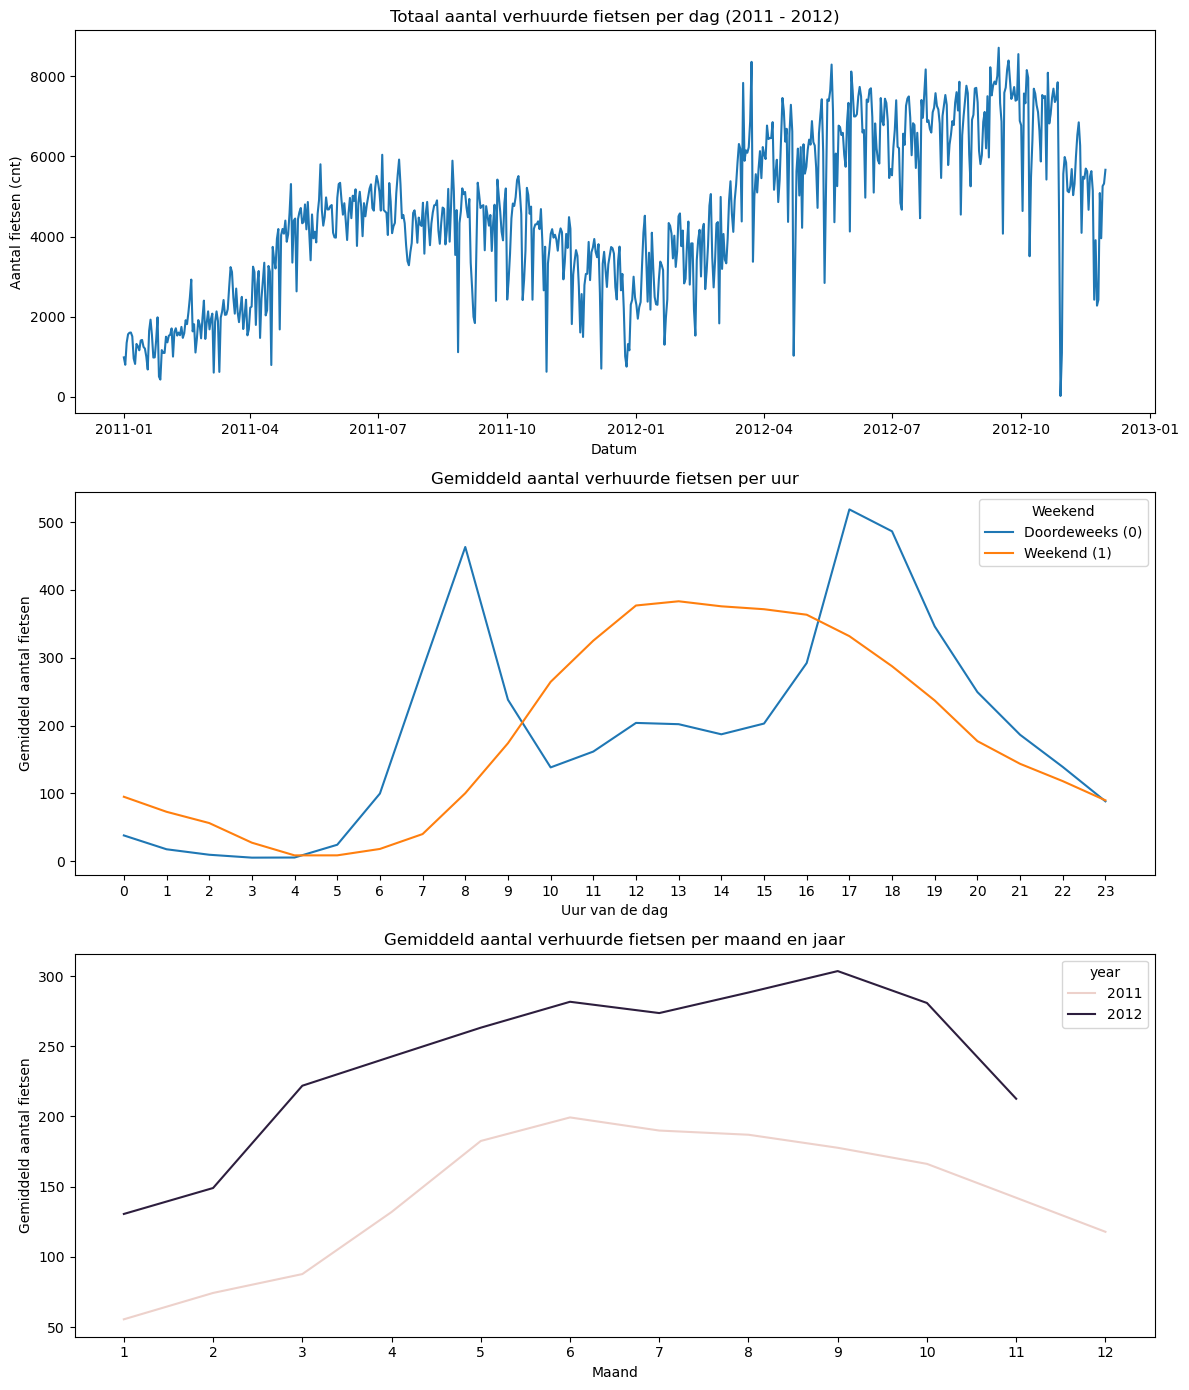

In [23]:
def plot_time_patterns(dataframe):
    """Plot het verloop per dag, per uur (weekend vs. doordeweeks) en per maand."""
    fig, axes = plt.subplots(3, 1, figsize=(12, 14))

    # 1. Dagelijks totaal over de hele periode (resample("D") groepeert per dag)
    daily_cnt = dataframe["cnt"].resample("D").sum()
    axes[0].plot(daily_cnt.index, daily_cnt.values)
    axes[0].set_title("Totaal aantal verhuurde fietsen per dag (2011 - 2012)")
    axes[0].set_xlabel("Datum")
    axes[0].set_ylabel("Aantal fietsen (cnt)")

    # 2. Gemiddelde per uur: doordeweeks vs. weekend
    sns.lineplot(
        data=dataframe,
        x="hour",
        y="cnt",
        hue="is_weekend",
        ax=axes[1],
        errorbar=None,
    )
    axes[1].set_title("Gemiddeld aantal verhuurde fietsen per uur")
    axes[1].set_xlabel("Uur van de dag")
    axes[1].set_ylabel("Gemiddeld aantal fietsen")
    axes[1].set_xticks(range(0, 24))
    axes[1].legend(title="Weekend", labels=["Doordeweeks (0)", "Weekend (1)"])

    # 3. Gemiddelde per maand, gesplitst per jaar
    sns.lineplot(
        data=dataframe,
        x="month",
        y="cnt",
        hue="year",
        ax=axes[2],
        errorbar=None,
    )
    axes[2].set_title("Gemiddeld aantal verhuurde fietsen per maand en jaar")
    axes[2].set_xlabel("Maand")
    axes[2].set_ylabel("Gemiddeld aantal fietsen")
    axes[2].set_xticks(range(1, 13))

    plt.tight_layout()
    plt.show()


plot_time_patterns(df_eda)
